In [1]:
!wget -O PdM_telemetry.csv https://azuremlsampleexperiments.blob.core.windows.net/datasets/PdM_telemetry.csv

--2026-09-28 09:50:58--  https://azuremlsampleexperiments.blob.core.windows.net/datasets/PdM_telemetry.csv
Resolving azuremlsampleexperiments.blob.core.windows.net (azuremlsampleexperiments.blob.core.windows.net)... failed: Name or service not known.
wget: unable to resolve host address ‘azuremlsampleexperiments.blob.core.windows.net’


In [2]:
import pandas as pd
import numpy as np

maint = pd.read_csv('/content/maint.csv')
machines = pd.read_csv('/content/machines.csv')
failures = pd.read_csv('/content/failures.csv')

print("Maintenance:", maint.shape)
print("Machines:", machines.shape)
print("Failures:", failures.shape)

Maintenance: (3286, 3)
Machines: (100, 3)
Failures: (761, 3)


In [3]:
print("Maintenance columns:")
print(maint.columns.tolist())

print("\nMachines columns:")
print(machines.columns.tolist())

print("\nFailures columns:")
print(failures.columns.tolist())

Maintenance columns:
['datetime', 'machineID', 'comp']

Machines columns:
['machineID', 'model', 'age']

Failures columns:
['datetime', 'machineID', 'failure']


In [4]:
display(maint.head())
display(machines.head())
display(failures.head())

,datetime,machineID,comp
0,6/1/2014 6:00:00 AM,1,comp2
1,7/16/2014 6:00:00 AM,1,comp4
2,7/31/2014 6:00:00 AM,1,comp3
3,12/13/2014 6:00:00 AM,1,comp1
4,1/5/2015 6:00:00 AM,1,comp4


,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2


,datetime,machineID,failure
0,1/5/2015 6:00:00 AM,1,comp4
1,3/6/2015 6:00:00 AM,1,comp1
2,4/20/2015 6:00:00 AM,1,comp2
3,6/19/2015 6:00:00 AM,1,comp4
4,9/2/2015 6:00:00 AM,1,comp4


In [6]:
print("Missing values - Maintenance")
print(maint.isnull().sum())

print("\nMissing values - Machines")
print(machines.isnull().sum())

print("\nMissing values - Failures")
print(failures.isnull().sum())

Missing values - Maintenance
datetime     0
machineID    0
comp         0
dtype: int64

Missing values - Machines
machineID    0
model        0
age          0
dtype: int64

Missing values - Failures
datetime     0
machineID    0
failure      0
dtype: int64


In [7]:
print("Duplicate rows - Maintenance:", maint.duplicated().sum())
print("Duplicate rows - Machines:", machines.duplicated().sum())
print("Duplicate rows - Failures:", failures.duplicated().sum())

Duplicate rows - Maintenance: 0
Duplicate rows - Machines: 0
Duplicate rows - Failures: 0


In [8]:
print("Maintenance:")
print(maint.dtypes)

print("\nMachines:")
print(machines.dtypes)

print("\nFailures:")
print(failures.dtypes)

Maintenance:
datetime     object
machineID     int64
comp         object
dtype: object

Machines:
machineID     int64
model        object
age           int64
dtype: object

Failures:
datetime     object
machineID     int64
failure      object
dtype: object


In [9]:
maint['datetime'] = pd.to_datetime(maint['datetime'], errors='coerce')
failures['datetime'] = pd.to_datetime(failures['datetime'], errors='coerce')

In [10]:
print(maint['datetime'].dtype)
print(failures['datetime'].dtype)

datetime64[ns]
datetime64[ns]


In [11]:
maintenance_machines = set(maint['machineID'].unique())
failure_machines = set(failures['machineID'].unique())
known_machines = set(machines['machineID'].unique())

print("Maintenance machine IDs not found in machines table:",
      len(maintenance_machines - known_machines))

print("Failure machine IDs not found in machines table:",
      len(failure_machines - known_machines))

Maintenance machine IDs not found in machines table: 0
Failure machine IDs not found in machines table: 0


In [12]:
print("===== DATASET SUMMARY =====")
print("Maintenance records:", len(maint))
print("Machine records:", len(machines))
print("Failure records:", len(failures))

print("\nMissing values:")
print("Maintenance:", maint.isnull().sum().sum())
print("Machines:", machines.isnull().sum().sum())
print("Failures:", failures.isnull().sum().sum())

print("\nDuplicate rows:")
print("Maintenance:", maint.duplicated().sum())
print("Machines:", machines.duplicated().sum())
print("Failures:", failures.duplicated().sum())

===== DATASET SUMMARY =====
Maintenance records: 3286
Machine records: 100
Failure records: 761

Missing values:
Maintenance: 0
Machines: 0
Failures: 0

Duplicate rows:
Maintenance: 0
Machines: 0
Failures: 0


In [13]:
print("===== DATASET SUMMARY =====")
print("Maintenance records:", len(maint))
print("Machine records:", len(machines))
print("Failure records:", len(failures))

print("\nMissing values:")
print("Maintenance:", maint.isnull().sum().sum())
print("Machines:", machines.isnull().sum().sum())
print("Failures:", failures.isnull().sum().sum())

print("\nDuplicate rows:")
print("Maintenance:", maint.duplicated().sum())
print("Machines:", machines.duplicated().sum())
print("Failures:", failures.duplicated().sum())

===== DATASET SUMMARY =====
Maintenance records: 3286
Machine records: 100
Failure records: 761

Missing values:
Maintenance: 0
Machines: 0
Failures: 0

Duplicate rows:
Maintenance: 0
Machines: 0
Failures: 0


In [14]:
machines['model'].value_counts()

,count
model,
model3,35
model4,32
model2,17
model1,16


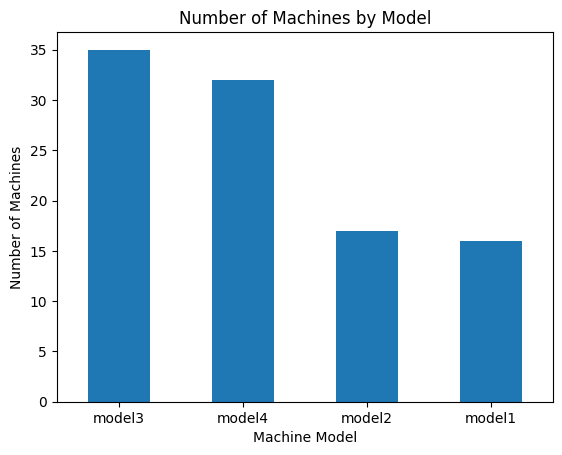

In [15]:
import matplotlib.pyplot as plt

machines['model'].value_counts().plot(kind='bar')

plt.title("Number of Machines by Model")
plt.xlabel("Machine Model")
plt.ylabel("Number of Machines")
plt.xticks(rotation=0)
plt.show()

In [16]:
maintenance_frequency = (
    maint.groupby('machineID')
    .size()
    .reset_index(name='Maintenance_Count')
    .sort_values('Maintenance_Count', ascending=False)
)

display(maintenance_frequency.head(10))

,machineID,Maintenance_Count
65,66,39
69,70,39
67,68,39
23,24,38
41,42,38
26,27,38
13,14,38
83,84,38
9,10,38
6,7,37


In [17]:
failure_frequency = (
    failures.groupby('machineID')
    .size()
    .reset_index(name='Failure_Count')
    .sort_values('Failure_Count', ascending=False)
)

display(failure_frequency.head(10))

,machineID,Failure_Count
96,99,19
95,98,16
20,22,15
15,17,15
80,83,14
35,37,14
18,20,13
11,13,13
14,16,13
69,71,13


In [18]:
machine_analysis = pd.merge(
    maintenance_frequency,
    failure_frequency,
    on='machineID',
    how='outer'
)

machine_analysis = machine_analysis.fillna(0)

machine_analysis = machine_analysis.sort_values(
    'Maintenance_Count',
    ascending=False
)

display(machine_analysis.head(15))

,machineID,Maintenance_Count,Failure_Count
65,66,39,5.0
69,70,39,5.0
67,68,39,4.0
23,24,38,10.0
41,42,38,9.0
26,27,38,3.0
13,14,38,4.0
83,84,38,7.0
9,10,38,5.0
6,7,37,10.0


In [19]:
machine_analysis = machine_analysis.merge(
    machines[['machineID', 'model']],
    on='machineID',
    how='left'
)

display(machine_analysis.head(15))

,machineID,Maintenance_Count,Failure_Count,model
0,66,39,5.0,model4
1,70,39,5.0,model3
2,68,39,4.0,model3
3,24,38,10.0,model1
4,42,38,9.0,model1
5,27,38,3.0,model3
6,14,38,4.0,model3
7,84,38,7.0,model3
8,10,38,5.0,model3
9,7,37,10.0,model3


In [20]:
model_analysis = (
    machine_analysis
    .groupby('model')[['Maintenance_Count', 'Failure_Count']]
    .mean()
    .round(2)
)

display(model_analysis)

,Maintenance_Count,Failure_Count
model,,
model1,32.62,11.81
model2,32.53,9.88
model3,33.49,6.31
model4,32.47,5.72


In [21]:
failures['failure'].value_counts()

,count
failure,
comp2,259
comp1,192
comp4,179
comp3,131


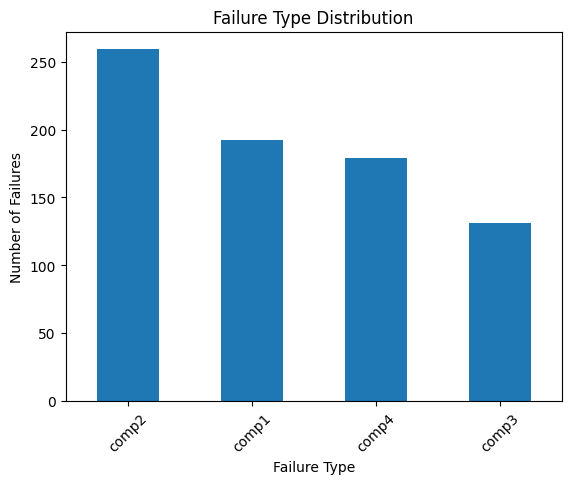

In [22]:
failures['failure'].value_counts().plot(kind='bar')

plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")
plt.xticks(rotation=45)
plt.show()

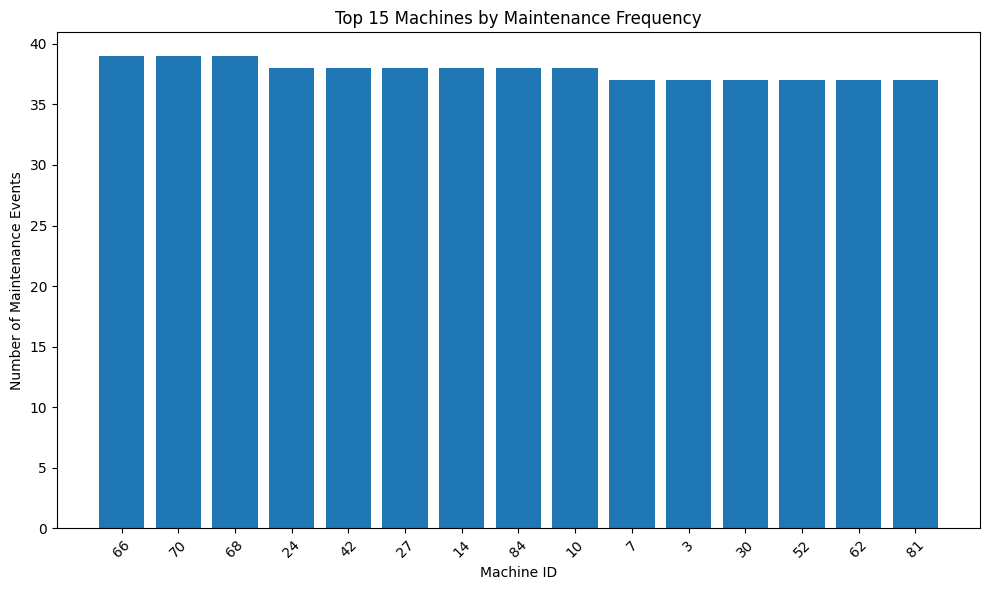

In [24]:
import matplotlib.pyplot as plt

top_maintenance = maintenance_frequency.head(15)

plt.figure(figsize=(10, 6))
plt.bar(
    top_maintenance['machineID'].astype(str),
    top_maintenance['Maintenance_Count']
)

plt.title("Top 15 Machines by Maintenance Frequency")
plt.xlabel("Machine ID")
plt.ylabel("Number of Maintenance Events")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

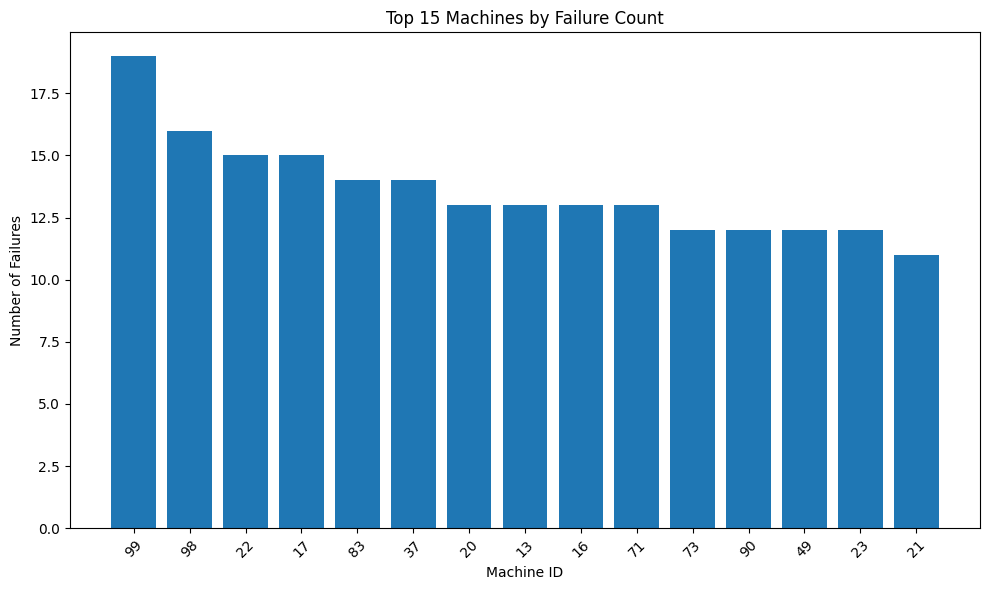

In [25]:
top_failures = failure_frequency.head(15)

plt.figure(figsize=(10, 6))
plt.bar(
    top_failures['machineID'].astype(str),
    top_failures['Failure_Count']
)

plt.title("Top 15 Machines by Failure Count")
plt.xlabel("Machine ID")
plt.ylabel("Number of Failures")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

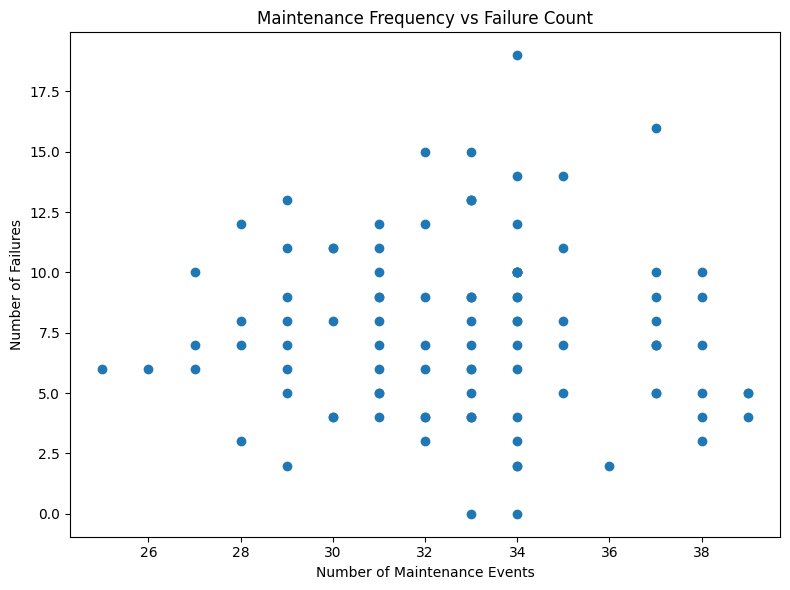

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(
    machine_analysis['Maintenance_Count'],
    machine_analysis['Failure_Count']
)

plt.title("Maintenance Frequency vs Failure Count")
plt.xlabel("Number of Maintenance Events")
plt.ylabel("Number of Failures")

plt.tight_layout()
plt.show()

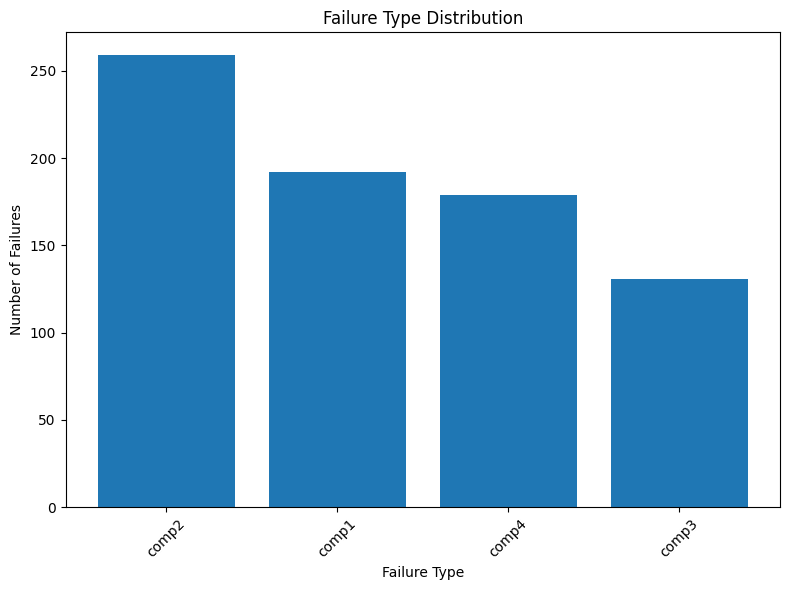

In [27]:
failure_types = failures['failure'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(
    failure_types.index,
    failure_types.values
)

plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
plt.savefig("maintenance_frequency.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [29]:
plt.savefig("maintenance_frequency.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [30]:
maint['datetime'] = pd.to_datetime(maint['datetime'])
failures['datetime'] = pd.to_datetime(failures['datetime'])

maint = maint.sort_values(['machineID', 'datetime'])
failures = failures.sort_values(['machineID', 'datetime'])

In [31]:
results = []

for _, m in maint.iterrows():
    machine = m['machineID']
    maintenance_date = m['datetime']

    machine_failures = failures[
        failures['machineID'] == machine
    ]

    before = machine_failures[
        (machine_failures['datetime'] < maintenance_date) &
        (machine_failures['datetime'] >= maintenance_date - pd.Timedelta(days=30))
    ]

    after = machine_failures[
        (machine_failures['datetime'] > maintenance_date) &
        (machine_failures['datetime'] <= maintenance_date + pd.Timedelta(days=30))
    ]

    results.append({
        'machineID': machine,
        'maintenance_date': maintenance_date,
        'failures_before_30d': len(before),
        'failures_after_30d': len(after)
    })

before_after = pd.DataFrame(results)

display(before_after.head())

,machineID,maintenance_date,failures_before_30d,failures_after_30d
0,1,2014-06-01 06:00:00,0,0
1,1,2014-07-16 06:00:00,0,0
2,1,2014-07-31 06:00:00,0,0
3,1,2014-12-13 06:00:00,0,1
4,1,2015-01-05 06:00:00,0,0


In [32]:
before_total = before_after['failures_before_30d'].sum()
after_total = before_after['failures_after_30d'].sum()

print("Total failures in 30 days BEFORE maintenance:", before_total)
print("Total failures in 30 days AFTER maintenance:", after_total)

if before_total > 0:
    change = ((after_total - before_total) / before_total) * 100
    print(f"Change after maintenance: {change:.2f}%")

Total failures in 30 days BEFORE maintenance: 1696
Total failures in 30 days AFTER maintenance: 1515
Change after maintenance: -10.67%


In [33]:
machine_before_after = (
    before_after
    .groupby('machineID')[['failures_before_30d', 'failures_after_30d']]
    .sum()
    .reset_index()
)

machine_before_after['change'] = (
    machine_before_after['failures_after_30d'] -
    machine_before_after['failures_before_30d']
)

display(
    machine_before_after
    .sort_values('change', ascending=False)
    .head(15)
)

,machineID,failures_before_30d,failures_after_30d,change
1,2,6,10,4
27,28,9,13,4
86,87,16,20,4
66,67,20,24,4
95,96,8,11,3
91,92,19,22,3
8,9,21,24,3
69,70,11,13,2
30,31,15,17,2
67,68,10,12,2


In [34]:
attention_machines = machine_before_after[
    machine_before_after['failures_after_30d'] >
    machine_before_after['failures_before_30d']
]

display(
    attention_machines
    .sort_values('change', ascending=False)
    .head(10)
)

,machineID,failures_before_30d,failures_after_30d,change
1,2,6,10,4
27,28,9,13,4
66,67,20,24,4
86,87,16,20,4
8,9,21,24,3
95,96,8,11,3
91,92,19,22,3
30,31,15,17,2
21,22,32,34,2
78,79,22,24,2


In [35]:
machine_analysis['Maintenance_Count'] = machine_analysis['Maintenance_Count'].astype(int)
machine_analysis['Failure_Count'] = machine_analysis['Failure_Count'].astype(int)

maintenance_median = machine_analysis['Maintenance_Count'].median()
failure_median = machine_analysis['Failure_Count'].median()

excessive_maintenance = machine_analysis[
    (machine_analysis['Maintenance_Count'] > maintenance_median) &
    (machine_analysis['Failure_Count'] > failure_median)
]

display(
    excessive_maintenance
    .sort_values(
        ['Maintenance_Count', 'Failure_Count'],
        ascending=False
    )
)

,machineID,Maintenance_Count,Failure_Count,model
3,24,38,10,model1
4,42,38,9,model1
17,98,37,16,model2
9,7,37,10,model3
16,95,37,9,model2
14,81,37,8,model4
22,37,35,14,model1
19,35,35,11,model1
23,63,35,8,model4
40,99,34,19,model1


In [39]:
category_summary = (
    machine_analysis
    .groupby('model')
    .agg(
        Machines=('machineID', 'count'),
        Total_Maintenance=('Maintenance_Count', 'sum'),
        Total_Failures=('Failure_Count', 'sum'),
        Avg_Maintenance=('Maintenance_Count', 'mean'),
        Avg_Failures=('Failure_Count', 'mean')
    )
    .round(2)
    .reset_index()
)

display(category_summary)

,model,Machines,Total_Maintenance,Total_Failures,Avg_Maintenance,Avg_Failures
0,model1,16,522,189,32.62,11.81
1,model2,17,553,168,32.53,9.88
2,model3,35,1172,221,33.49,6.31
3,model4,32,1039,183,32.47,5.72


In [40]:
category_summary['Failures_per_Maintenance'] = (
    category_summary['Total_Failures'] /
    category_summary['Total_Maintenance']
).round(3)

display(category_summary)

,model,Machines,Total_Maintenance,Total_Failures,Avg_Maintenance,Avg_Failures,Failures_per_Maintenance
0,model1,16,522,189,32.62,11.81,0.362
1,model2,17,553,168,32.53,9.88,0.304
2,model3,35,1172,221,33.49,6.31,0.189
3,model4,32,1039,183,32.47,5.72,0.176


In [41]:
maintenance_median = machine_analysis['Maintenance_Count'].median()
failure_median = machine_analysis['Failure_Count'].median()

attention_machines = machine_analysis[
    (machine_analysis['Maintenance_Count'] > maintenance_median) &
    (machine_analysis['Failure_Count'] > failure_median)
].copy()

attention_machines = attention_machines.sort_values(
    ['Failure_Count', 'Maintenance_Count'],
    ascending=False
)

display(attention_machines)

,machineID,Maintenance_Count,Failure_Count,model
40,99,34,19,model1
17,98,37,16,model2
22,37,35,14,model1
34,83,34,14,model4
42,90,34,12,model2
19,35,35,11,model1
3,24,38,10,model1
9,7,37,10,model3
24,43,34,10,model3
30,32,34,10,model4


In [42]:
excessive_maintenance = machine_analysis[
    (machine_analysis['Maintenance_Count'] > maintenance_median) &
    (machine_analysis['Failure_Count'] >= failure_median)
].copy()

display(
    excessive_maintenance[
        ['machineID', 'model', 'Maintenance_Count', 'Failure_Count']
    ].sort_values(
        'Maintenance_Count',
        ascending=False
    )
)

,machineID,model,Maintenance_Count,Failure_Count
3,24,model1,38,10
4,42,model1,38,9
7,84,model3,38,7
9,7,model3,37,10
12,52,model3,37,7
13,62,model4,37,7
14,81,model4,37,8
15,1,model3,37,7
16,95,model2,37,9
17,98,model2,37,16


In [43]:
model_data = machine_analysis.copy()

# Create target:
# 1 = machine has at least one failure
# 0 = no recorded failure
model_data['Failure_Target'] = (
    model_data['Failure_Count'] > 0
).astype(int)

display(model_data.head())

,machineID,Maintenance_Count,Failure_Count,model,Failure_Target
0,66,39,5,model4,1
1,70,39,5,model3,1
2,68,39,4,model3,1
3,24,38,10,model1,1
4,42,38,9,model1,1


In [44]:
model_data = model_data.merge(
    machines[['machineID', 'age']],
    on='machineID',
    how='left'
)

display(model_data.head())

,machineID,Maintenance_Count,Failure_Count,model,Failure_Target,age
0,66,39,5,model4,1,6
1,70,39,5,model3,1,9
2,68,39,4,model3,1,10
3,24,38,10,model1,1,20
4,42,38,9,model1,1,7


In [45]:
X = model_data[
    ['model', 'age', 'Maintenance_Count']
]

y = model_data['Failure_Target']

print("Features:")
display(X.head())

print("\nTarget:")
print(y.value_counts())

Features:


,model,age,Maintenance_Count
0,model4,6,39
1,model3,9,39
2,model3,10,39
3,model1,20,38
4,model1,7,38



Target:
Failure_Target
1    98
0     2
Name: count, dtype: int64


In [46]:
X = pd.get_dummies(
    X,
    columns=['model'],
    drop_first=True
)

display(X.head())

,age,Maintenance_Count,model_model2,model_model3,model_model4
0,6,39,False,False,True
1,9,39,False,True,False
2,10,39,False,True,False
3,20,38,False,False,False
4,7,38,False,False,False


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


In [48]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [49]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1]


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.9
Precision: 1.0
Recall   : 0.9
F1 Score : 0.947

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.90      0.95        20

    accuracy                           0.90        20
   macro avg       0.50      0.45      0.47        20
weighted avg       1.00      0.90      0.95        20



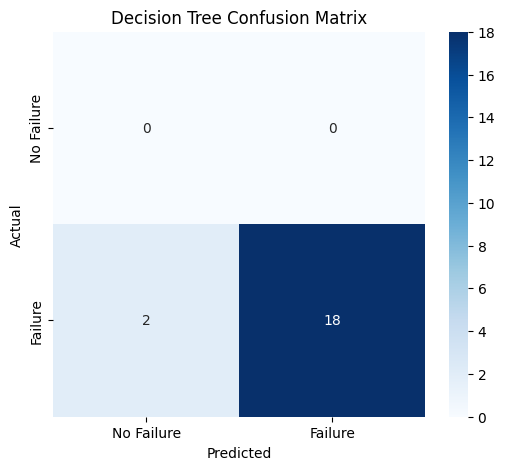

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [52]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,age,0.747275
1,Maintenance_Count,0.252725
2,model_model2,0.000000
3,model_model3,0.000000
4,model_model4,0.000000


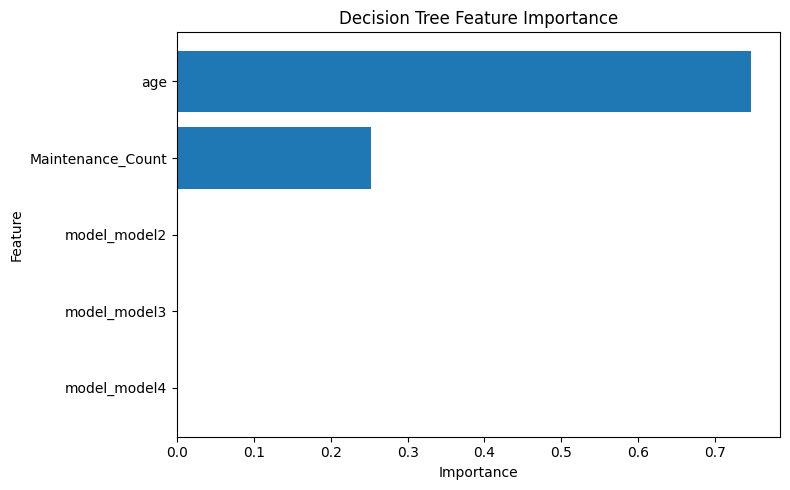

In [53]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [54]:
print("===== FINAL ANALYSIS SUMMARY =====")

print("\nTotal machines:", machines['machineID'].nunique())
print("Total maintenance events:", len(maint))
print("Total failure events:", len(failures))

print("\nAverage maintenance events per machine:",
      round(maint.groupby('machineID').size().mean(), 2))

print("Average failures per machine:",
      round(failures.groupby('machineID').size().mean(), 2))

print("\nMost common machine models:")
print(machines['model'].value_counts())

print("\nMost common failure types:")
print(failures['failure'].value_counts())

print("\nTop 10 machines by maintenance:")
display(maintenance_frequency.head(10))

print("\nTop 10 machines by failures:")
display(failure_frequency.head(10))

print("\nMachines requiring attention:")
display(attention_machines[['machineID', 'model',
                            'Maintenance_Count',
                            'Failure_Count']].head(10))

===== FINAL ANALYSIS SUMMARY =====

Total machines: 100
Total maintenance events: 3286
Total failure events: 761

Average maintenance events per machine: 32.86
Average failures per machine: 7.77

Most common machine models:
model
model3    35
model4    32
model2    17
model1    16
Name: count, dtype: int64

Most common failure types:
failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

Top 10 machines by maintenance:


,machineID,Maintenance_Count
65,66,39
69,70,39
67,68,39
23,24,38
41,42,38
26,27,38
13,14,38
83,84,38
9,10,38
6,7,37



Top 10 machines by failures:


,machineID,Failure_Count
96,99,19
95,98,16
20,22,15
15,17,15
80,83,14
35,37,14
18,20,13
11,13,13
14,16,13
69,71,13



Machines requiring attention:


,machineID,model,Maintenance_Count,Failure_Count
40,99,model1,34,19
17,98,model2,37,16
22,37,model1,35,14
34,83,model4,34,14
42,90,model2,34,12
19,35,model1,35,11
3,24,model1,38,10
9,7,model3,37,10
24,43,model3,34,10
30,32,model4,34,10
